# Module 02: A Box Model of Land-Atmosphere Carbon Balance

### Assignment: Parts A, B and C



## Problem A: Modify and rerun the model

Model parameters

In [2]:
import numpy as np
import matplotlib.pyplot as plt

M1i = 1100.0 # Initial carbon storage in the atmosphere (GtC)
M2i = 300.0 # Initial carbon storage in the land (GtC)

k12 = 0.0003 # Rate constant for carbon transfer from atmosphere to land, photosynthesis (1/(GtC yr))
k21 = 0.1 # Rate constant for carbon transfer from land to atmosphere, respiration and decay (1/yr)

ti = 0.0 # Initial time (yr)
tf = 100 # Final time (yr)
dt = 1/365 # Time step (yr)

#### Run the unforced simulation for 100 years with a daily time step

In [12]:
t = np.arange(ti,tf+dt,dt) # Array of time steps from initial to final time

Nt = t.size

print('t has '+str(Nt)+' time steps')

t has 36501 time steps


In [13]:
M1 = np.zeros((Nt,)) # Empty array to hold atmospheric carbon at every time step
M2 = np.zeros((Nt,)) # Empty array to hold land carbon at every time step

In [14]:
for i in np.arange(Nt):
    if (i==0): # Initialize the first time step with the initial conditions

        M1[i] = M1i
        M2[i] = M2i
        
    else:
        dM1dt = k21*M2[i-1] - k12*M1[i-1]*M2[i-1] # Respiration minus photosynthesis (photosynthesis now depends on both M1 and M2)
        dM2dt = k12*M1[i-1]*M2[i-1] - k21*M2[i-1] # Photosynthesis minus respiration
        
        M1[i] = M1[i-1] + dM1dt*dt # Step the atmosphere forward one time step
        M2[i] = M2[i-1] + dM2dt*dt # Step the land forward one time step


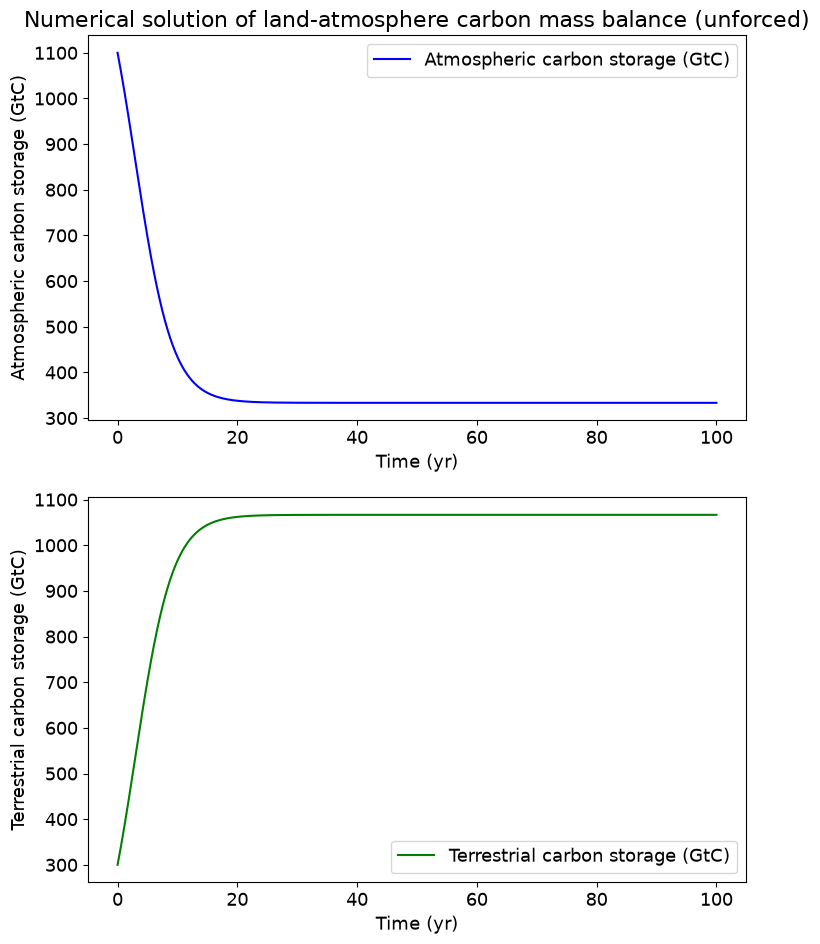

In [15]:
plt.figure(figsize=(8.5,11))
plt.rcParams.update({'font.size': 13})

plt.subplot(2,1,1)
plt.title('Numerical solution of land-atmosphere carbon mass balance (unforced)')
plt.plot(t,M1,'b-', label='Atmospheric carbon storage (GtC)') # Mass of C in the atmosphere vs. time
plt.xlabel('Time (yr)')
plt.ylabel('Atmospheric carbon storage (GtC)')
plt.legend()

plt.subplot(2,1,2)
plt.plot(t,M2,'g-', label='Terrestrial carbon storage (GtC)') # Mass of C in the land vs. time
plt.xlabel('Time (yr)')
plt.ylabel('Terrestrial carbon storage (GtC)')
plt.legend()

plt.show()

#### Print the final values of M1 and M2

In [7]:
M1_A = M1[-1] # Save the final atmospheric carbon from Problem A (used as the starting value in Problem B)
M2_A = M2[-1] # Save the final land carbon from Problem A (used as the starting value in Problem B)

print('Final M1 (atmosphere) = '+str(M1_A)+' GtC')
print('Final M2 (land) = '+str(M2_A)+' GtC')

Final M1 (atmosphere) = 333.3333333333658 GtC
Final M2 (land) = 1066.6666666665792 GtC


## Problem B

#### Loading the anthropogenic emissions data

In [8]:
historical_emissions_file = 'AnthropogenicEmissions.1751_2008.csv' # Name of the emissions file (must be in the same folder as this notebook)

data = np.loadtxt(historical_emissions_file, delimiter=',', skiprows=1) # Read the comma separated file, skipping the one header row
year = data[:,0] # First column: year
cflux = data[:,1] # Second column: anthropogenic emissions (GtC/yr)

print('Emissions data has '+str(year.size)+' years, from '+str(int(year[0]))+' to '+str(int(year[-1]))) # Check that the file loaded as expected

Emissions data has 258 years, from 1751 to 2008


#### Plotting our actions

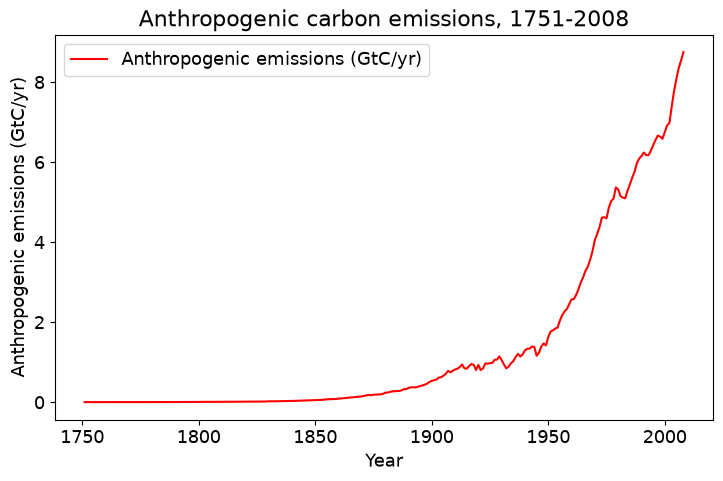

In [11]:
plt.figure(figsize=(8.5,5))
plt.rcParams.update({'font.size': 13})

plt.title('Anthropogenic carbon emissions, 1751-2008')
plt.plot(year,cflux,'r-', label='Anthropogenic emissions (GtC/yr)') # Annual emissions vs. year
plt.xlabel('Year')
plt.ylabel('Anthropogenic emissions (GtC/yr)')
plt.legend()

plt.show()

#### Simulate the response of carbon to emissions

In [9]:
M1i = M1_A # Initial carbon storage in the atmosphere (GtC) = final M1 from Problem A(3)
M2i = M2_A # Initial carbon storage in the land (GtC) = final M2 from Problem A(3)

ti = 1751.0 # Initial time (yr) = first year of the emissions data
tf = 2008.0 # Final time (yr) = last year of the emissions data
dt = 1/365 # Time step (yr)

In [10]:
t = np.arange(ti,tf+dt,dt) # Array of time steps from initial to final time

Nt = t.size

print('t has '+str(Nt)+' time steps')

t has 93806 time steps


In [11]:
cflux_t = np.interp(t, year, cflux) # Interpolate the annual emissions onto the daily model time steps (GtC/yr)

In [12]:
M1 = np.zeros((Nt,)) # Empty array to hold atmospheric carbon at every time step
M2 = np.zeros((Nt,)) # Empty array to hold land carbon at every time step

In [13]:
for i in np.arange(Nt):
    if (i==0): # Initialize the first time step with the initial conditions

        M1[i] = M1i
        M2[i] = M2i
        
    else:
        dM1dt = k21*M2[i-1] - k12*M1[i-1]*M2[i-1] + cflux_t[i-1] # Respiration minus photosynthesis, plus the emissions source term (added to the atmosphere)
        dM2dt = k12*M1[i-1]*M2[i-1] - k21*M2[i-1] # Photosynthesis minus respiration (no direct emissions into the land)
        
        M1[i] = M1[i-1] + dM1dt*dt # Step the atmosphere forward one time step
        M2[i] = M2[i-1] + dM2dt*dt # Step the land forward one time step


In [14]:
dM1 = np.diff(M1)/dt # Change in atmospheric carbon between consecutive time steps, divided by dt to give a rate (GtC/yr)
dM2 = np.diff(M2)/dt # Change in land carbon between consecutive time steps, divided by dt to give a rate (GtC/yr)

t_diff = t[1:] # np.diff returns one fewer value than M1, so drop the first time step to match

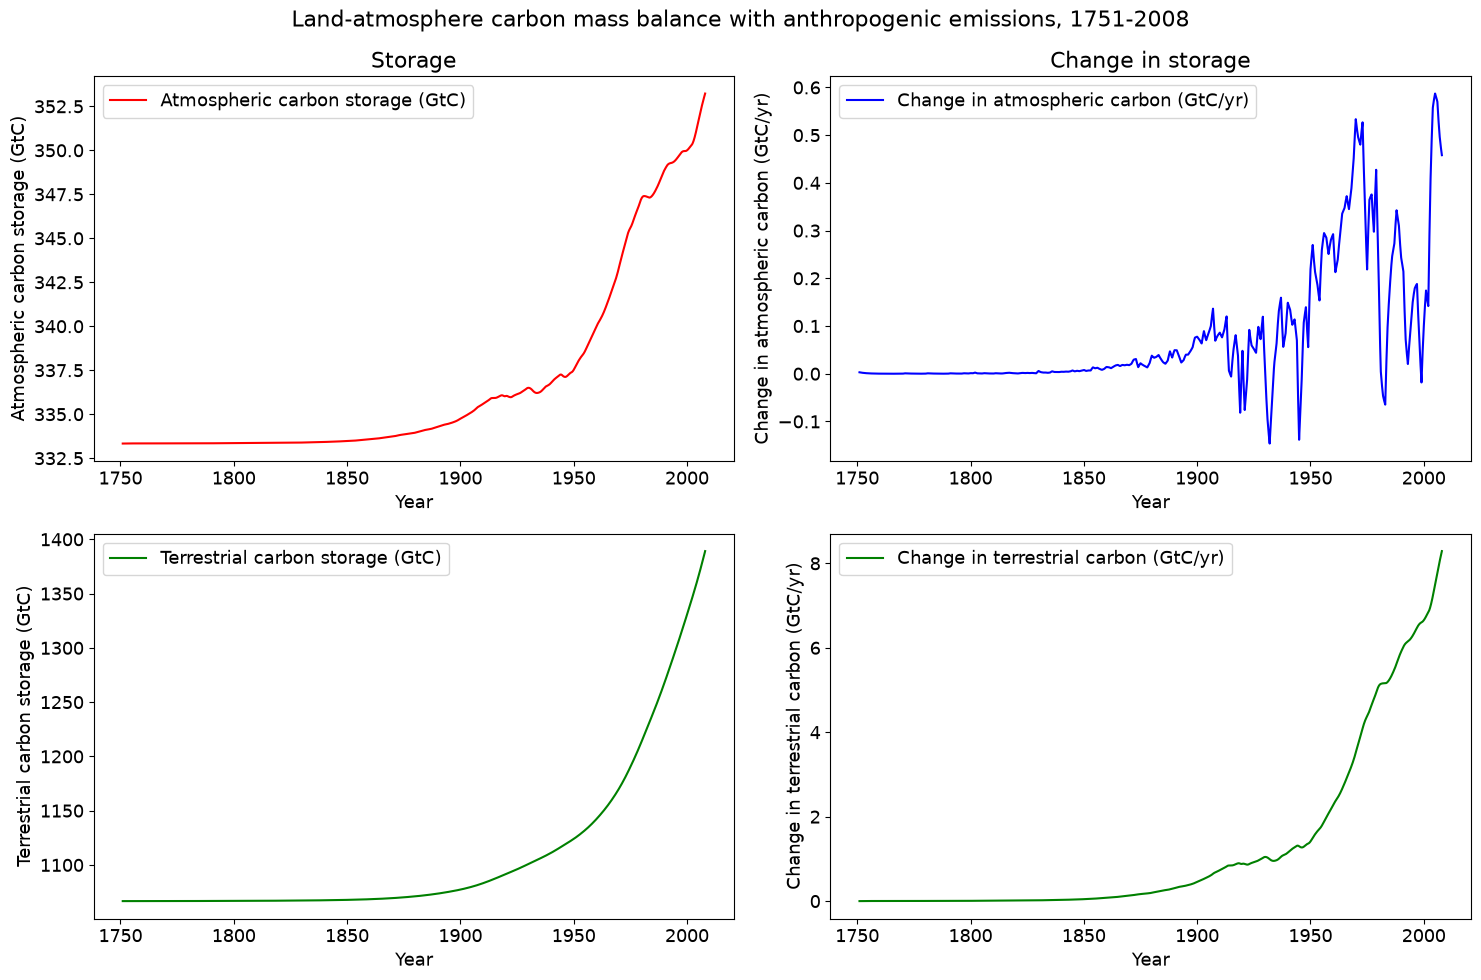

In [ ]:
plt.figure(figsize=(15,10)) # One figure with four panels: storage in the left column, change in the right column
plt.rcParams.update({'font.size': 13})
plt.suptitle('Land-atmosphere carbon mass balance with anthropogenic emissions, 1751-2008')

plt.subplot(2,2,1) # Top left: mass of C in the atmosphere vs. time
plt.title('Storage')
plt.plot(t,M1,'r-', label='Atmospheric carbon storage (GtC)')
plt.xlabel('Year')
plt.ylabel('Atmospheric carbon storage (GtC)')
plt.legend()

plt.subplot(2,2,2) # Top right: change in mass of C in the atmosphere vs. time
plt.title('Change in storage')
plt.plot(t_diff,dM1,'b-', label='Change in atmospheric carbon (GtC/yr)')
plt.xlabel('Year')
plt.ylabel('Change in atmospheric carbon (GtC/yr)')
plt.legend()

plt.subplot(2,2,3) # Bottom left: mass of C in the land vs. time
plt.plot(t,M2,'g-', label='Terrestrial carbon storage (GtC)')
plt.xlabel('Year')
plt.ylabel('Terrestrial carbon storage (GtC)')
plt.legend()

plt.subplot(2,2,4) # Bottom right: change in mass of C in the land vs. time
plt.plot(t_diff,dM2,'g-', label='Change in terrestrial carbon (GtC/yr)')
plt.xlabel('Year')
plt.ylabel('Change in terrestrial carbon (GtC/yr)')
plt.legend()

plt.tight_layout() # Adjust the spacing so the axis labels of neighboring panels do not overlap
plt.show()

In [18]:
M1_B = M1[-1] # Save the final atmospheric carbon from Problem B (used as the starting value in Problem C)
M2_B = M2[-1] # Save the final land carbon from Problem B (used as the starting value in Problem C)

print('Final M1 (atmosphere) in 2008 = '+str(M1_B)+' GtC')
print('Final M2 (land) in 2008 = '+str(M2_B)+' GtC')

Final M1 (atmosphere) in 2008 = 353.22824788827904 GtC
Final M2 (land) in 2008 = 1389.1417712620218 GtC


## Problem C: Mitigation scenarios

#### Load alternative emission scenarios

In [ ]:
future_emissions_file = 'EmissionsMitigationScenarios.2008_2100.csv' # Name of the scenarios file (must be in the same folder as this notebook)

data = np.loadtxt(future_emissions_file, delimiter=',', skiprows=1) # Read the comma separated file, skipping the one header row
year = data[:,0] # First column: year
cflux_nz2030 = data[:,1] # Second column: net zero emissions by 2030 (GtC/yr)
cflux_nz2050 = data[:,2] # Third column: net zero emissions by 2050 (GtC/yr)
cflux_zeg = data[:,3] # Fourth column: constant emissions from 2008 (GtC/yr)

print('Data contain '+str(year.size)+' years, from '+str(int(year[0]))+' to '+str(int(year[-1]))) # Check that the file loaded as expected

Data contain 93 years, from 2008 to 2100


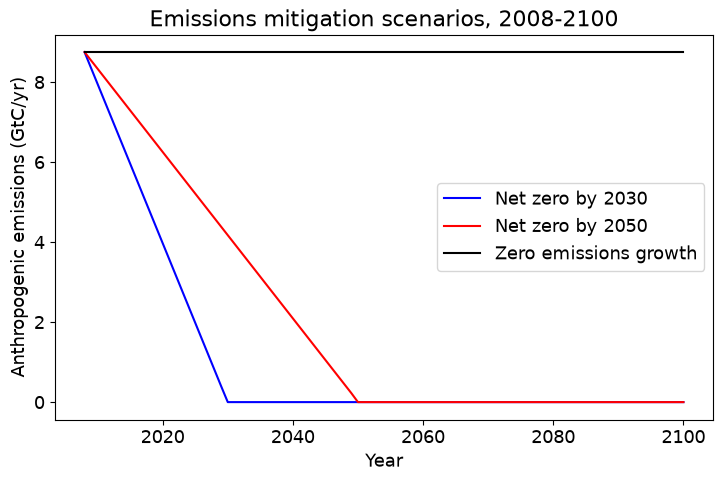

In [ ]:
plt.figure(figsize=(8.5,5))
plt.rcParams.update({'font.size': 13})

plt.title('Emissions mitigation scenarios, 2008-2100')
plt.plot(year,cflux_nz2030,'b-', label='Net zero by 2030') # Emissions for each scenario vs. year. Boy does that seem unrealistic... :(
plt.plot(year,cflux_nz2050,'r-', label='Net zero by 2050')
plt.plot(year,cflux_zeg,'k-', label='Zero emissions growth')
plt.xlabel('Year')
plt.ylabel('Anthropogenic emissions (GtC/yr)')
plt.legend()

plt.show() # Would have been better to plot a more gradual drop-off; this is just for fun.

#### Run the model for each scenario

In [ ]:
M1i = M1_B # Initial carbon storage in the atmosphere (GtC) = final M1 from Problem B
M2i = M2_B # Initial carbon storage in the land (GtC) = final M2 from Problem B

ti = 2008.0 # Initial time (yr) = first year of the scenario data
tf = 2100.0 # Final time (yr) = last year of the scenario data
dt = 1/365 # Time step (yr)

In [22]:
t = np.arange(ti,tf+dt,dt) # Array of time steps from initial to final time

Nt = t.size

print('t has '+str(Nt)+' time steps')

t has 33581 time steps


In [23]:
cflux_nz2030_t = np.interp(t, year, cflux_nz2030) # Interpolate each scenario's annual emissions onto the daily model time steps (GtC/yr)
cflux_nz2050_t = np.interp(t, year, cflux_nz2050)
cflux_zeg_t = np.interp(t, year, cflux_zeg)

In [ ]:
M1_nz2030 = np.zeros((Nt,)) # Empty arrays to hold atmospheric and land carbon for the net zero by 2030 scenario
M2_nz2030 = np.zeros((Nt,))

M1_nz2050 = np.zeros((Nt,)) # Ditto for: net zero by 2050 scenario
M2_nz2050 = np.zeros((Nt,))

M1_zeg = np.zeros((Nt,)) # Ditto for: zero emissions growth scenario
M2_zeg = np.zeros((Nt,))

In [ ]:
for i in np.arange(Nt):
    if (i==0): # Initialize the first time step of all three scenarios with the same initial conditions

        M1_nz2030[i] = M1i
        M2_nz2030[i] = M2i

        M1_nz2050[i] = M1i
        M2_nz2050[i] = M2i

        M1_zeg[i] = M1i
        M2_zeg[i] = M2i
        
    else:
        # Scenario 1: net zero emissions by 2030
        dM1dt = k21*M2_nz2030[i-1] - k12*M1_nz2030[i-1]*M2_nz2030[i-1] + cflux_nz2030_t[i-1] # Respiration minus photosynthesis, plus this scenario's emissions
        dM2dt = k12*M1_nz2030[i-1]*M2_nz2030[i-1] - k21*M2_nz2030[i-1] # Photosynthesis minus respiration
        
        M1_nz2030[i] = M1_nz2030[i-1] + dM1dt*dt # Step the atmosphere forward one time step
        M2_nz2030[i] = M2_nz2030[i-1] + dM2dt*dt # Step the land forward one time step

        # Scenario 2: net zero emissions by 2050
        dM1dt = k21*M2_nz2050[i-1] - k12*M1_nz2050[i-1]*M2_nz2050[i-1] + cflux_nz2050_t[i-1] # Respiration minus photosynthesis, plus this scenario's emissions
        dM2dt = k12*M1_nz2050[i-1]*M2_nz2050[i-1] - k21*M2_nz2050[i-1] # Photosynthesis minus respiration
        
        M1_nz2050[i] = M1_nz2050[i-1] + dM1dt*dt # Step the atmosphere forward one time step
        M2_nz2050[i] = M2_nz2050[i-1] + dM2dt*dt # Step the land forward one time step

        # Scenario 3: zero emissions growth held at constant
        dM1dt = k21*M2_zeg[i-1] - k12*M1_zeg[i-1]*M2_zeg[i-1] + cflux_zeg_t[i-1] # Respiration minus photosynthesis, plus this scenario's emissions
        dM2dt = k12*M1_zeg[i-1]*M2_zeg[i-1] - k21*M2_zeg[i-1] # Photosynthesis minus respiration
        
        M1_zeg[i] = M1_zeg[i-1] + dM1dt*dt # Step the atmosphere forward one time step
        M2_zeg[i] = M2_zeg[i-1] + dM2dt*dt # Step the land forward one time step


In [ ]:
dM1_nz2030 = np.diff(M1_nz2030)/dt # Change in atmospheric and land carbon for each scenario, divided by dt (GtC/yr)
dM2_nz2030 = np.diff(M2_nz2030)/dt

dM1_nz2050 = np.diff(M1_nz2050)/dt
dM2_nz2050 = np.diff(M2_nz2050)/dt

dM1_zeg = np.diff(M1_zeg)/dt
dM2_zeg = np.diff(M2_zeg)/dt

t_diff = t[1:] # np.diff returns one fewer value than M1, so drop the first time step to match

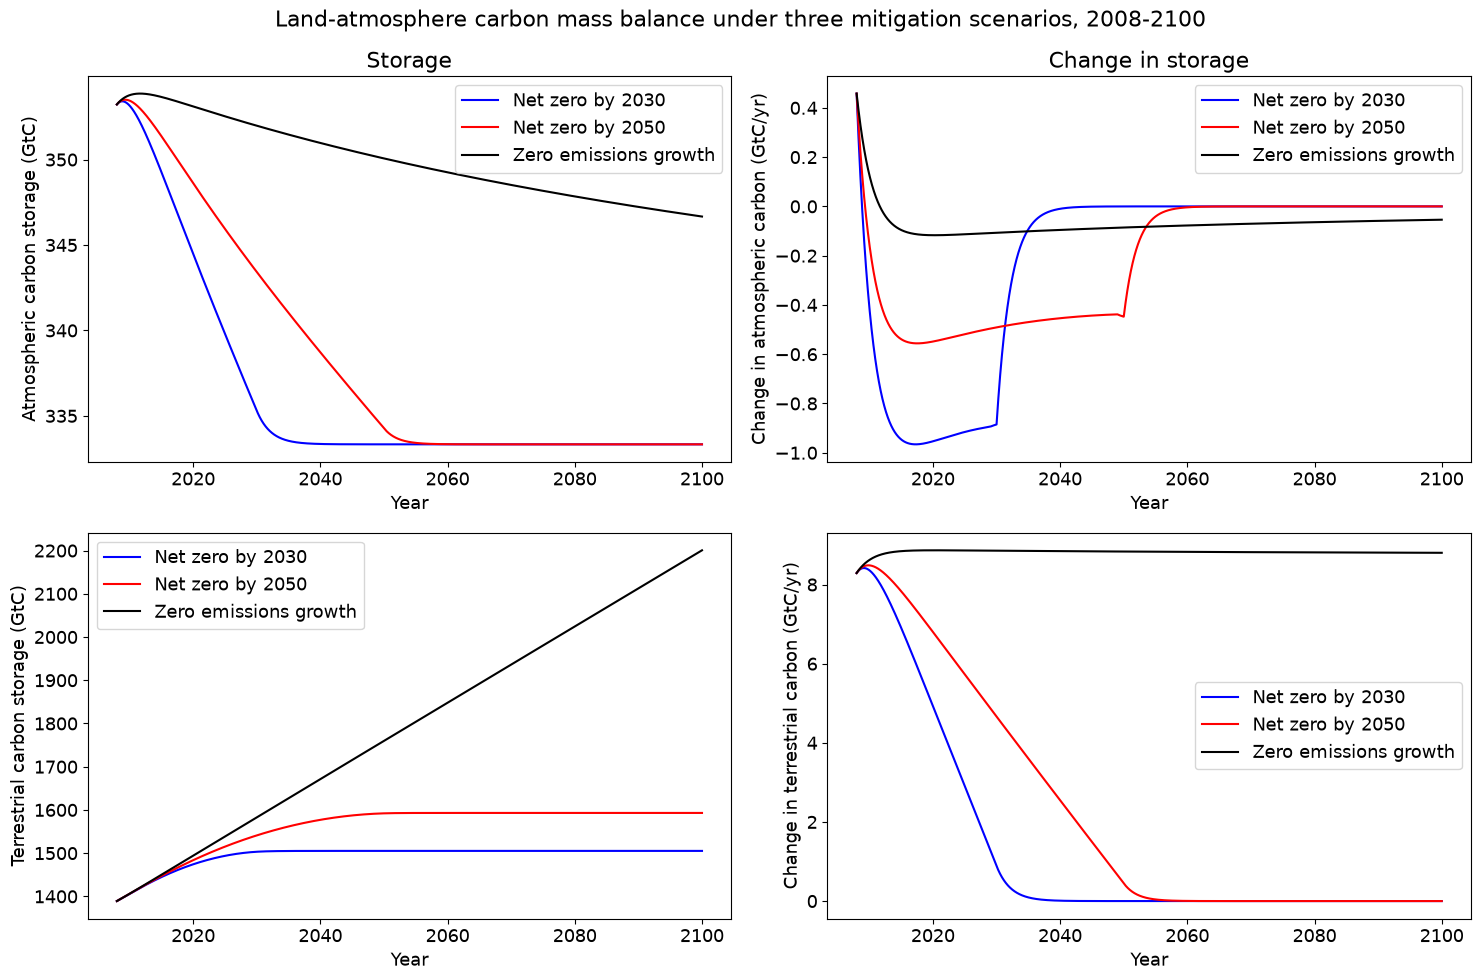

In [ ]:
plt.figure(figsize=(15,10)) # One figure with four panels: storage in the left column, change in the right column
plt.rcParams.update({'font.size': 13})
plt.suptitle('Land-atmosphere carbon mass balance under three mitigation scenarios, 2008-2100')

plt.subplot(2,2,1) # Top left: mass of C in the atmosphere vs. time (all three scenarios)
plt.title('Storage')
plt.plot(t,M1_nz2030,'b-', label='Net zero by 2030')
plt.plot(t,M1_nz2050,'r-', label='Net zero by 2050')
plt.plot(t,M1_zeg,'k-', label='Zero emissions growth')
plt.xlabel('Year')
plt.ylabel('Atmospheric carbon storage (GtC)')
plt.legend()

plt.subplot(2,2,2) # Top right: change in mass of C in the atmosphere vs. time (all three scenarios)
plt.title('Change in storage')
plt.plot(t_diff,dM1_nz2030,'b-', label='Net zero by 2030')
plt.plot(t_diff,dM1_nz2050,'r-', label='Net zero by 2050')
plt.plot(t_diff,dM1_zeg,'k-', label='Zero emissions growth')
plt.xlabel('Year')
plt.ylabel('Change in atmospheric carbon (GtC/yr)')
plt.legend()

plt.subplot(2,2,3) # Bottom left: mass of C in the land vs. time (all three scenarios)
plt.plot(t,M2_nz2030,'b-', label='Net zero by 2030')
plt.plot(t,M2_nz2050,'r-', label='Net zero by 2050')
plt.plot(t,M2_zeg,'k-', label='Zero emissions growth')
plt.xlabel('Year')
plt.ylabel('Terrestrial carbon storage (GtC)')
plt.legend()

plt.subplot(2,2,4) # Bottom right: change in mass of C in the land vs. time (all three scenarios)
plt.plot(t_diff,dM2_nz2030,'b-', label='Net zero by 2030')
plt.plot(t_diff,dM2_nz2050,'r-', label='Net zero by 2050')
plt.plot(t_diff,dM2_zeg,'k-', label='Zero emissions growth')
plt.xlabel('Year')
plt.ylabel('Change in terrestrial carbon (GtC/yr)')
plt.legend()

plt.tight_layout() # Adjust the spacing 
plt.show()

In [28]:
print('Net zero by 2030:      M1 = '+str(M1_nz2030[-1])+' GtC, M2 = '+str(M2_nz2030[-1])+' GtC') # Final values in 2100 for each scenario
print('Net zero by 2050:      M1 = '+str(M1_nz2050[-1])+' GtC, M2 = '+str(M2_nz2050[-1])+' GtC')
print('Zero emissions growth: M1 = '+str(M1_zeg[-1])+' GtC, M2 = '+str(M2_zeg[-1])+' GtC')

Net zero by 2030:      M1 = 333.33333333335634 GtC, M2 = 1505.214170749825 GtC
Net zero by 2050:      M1 = 333.3333333333751 GtC, M2 = 1593.0441707510918 GtC
Zero emissions growth: M1 = 346.6675284594091 GtC, M2 = 2200.6104906909054 GtC
